<a href="https://colab.research.google.com/github/asilbek1301/computer_vision/blob/main/menu_detector_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **DataSet 💠 Transform 💠 DataLoading 💠 FineTuning 💠 Testing**

In [2]:
print('MENU DETECTOR AI MODEL')

MENU DETECTOR AI MODEL


In [3]:
# --------------------------------
# Import Libraries
# --------------------------------

from google.colab import drive
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms     # import transformers
from torchvision.models import mobilenet_v2

from PIL import Image, UnidentifiedImageError
from torch.utils.data import Dataset, DataLoader
import os
import numpy as np

In [4]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
# --------------------------------
# Define Dataset Path
# --------------------------------

DATASET_PATH = '/content/drive/MyDrive/food101_dataset'


CUSTOM_CLASS_MAPPING = {
    "hamburger": "hamburger",
    "hot_dog": "hot_dog",
    "chocolate_cake": "dessert",    # label grouping | class consolidation
    "cheesecake": "dessert",        # label grouping | class consolidation
    "kebab": "kebab",
    "pilaf": "pilaf"
}


CLASSES = ['hamburger', 'hot_dog', 'dessert', 'kebab', 'pilaf']
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)

print(NUM_CLASSES)
print(CLASS_TO_IDX)


transform = transforms.Compose([                          # pipeline hosil qilib beradi
    transforms.Resize((224, 224)),                        # ishlatayotgan AI Modelning feature standardlaridan kelib chiqib resize, normilize qilinadi
    transforms.ToTensor(),                                # 0.0 ~ 1.0     Height, Width, Channel  =>  C, H, W       | RGB = 3 channels
    transforms.Normalize(mean=[0.485, 0.456, 0.406],      # hamma rasmlarni normal holatga keltiradi
                         std=[0.229, 0.224, 0.225])       # pixel = (pixel - mean) / std
])

5
{'hamburger': 0, 'hot_dog': 1, 'dessert': 2, 'kebab': 3, 'pilaf': 4}


In [6]:
# -----------------------
# Custom Dataset Class
# -----------------------

class FoodDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        # print('images_length', len(self.images))
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        # print('image_path', img_path)
        label = self.labels[idx]
        # print('label', label)
        try:
            image = Image.open(img_path)
            if image.mode == "P" or image.mode == "RGBA":
                image = image.convert("RGBA").convert("RGB")
            else:
                image = image.convert("RGB")                # 3 Channel
        except (UnidentifiedImageError, OSError):           # checking empty image
            print(f"Skipping broken image: {img_path}")
            return self.__getitem__((idx + 1) % len(self.images))
        if self.transform:
            image = self.transform(image)
        return image, label

In [7]:
# --------------------------
# Gather and Split Data
# --------------------------
all_images = []
for original_class, mapped_class in CUSTOM_CLASS_MAPPING.items():
    class_path = os.path.join(DATASET_PATH, original_class)                 # /content/drive/MyDrive/food101_dataset/hamburger
    print('class_path:', class_path)
    if not os.path.exists(class_path):
        print(f"Warning: {class_path} not found")
        continue
    for img in os.listdir(class_path):
        if img.endswith(('.jpg', '.jpeg', '.png')):                         # .txt .docx va boshqa turdagi fayllarni split qiladi
            full_path = os.path.join(class_path, img)                       # /content/drive/MyDrive/food101_dataset/hamburger/100057.jpg
            all_images.append((full_path, CLASS_TO_IDX[mapped_class]))

np.random.shuffle(all_images)             # hamma datalarni mix qilyapti
split = int(0.8 * len(all_images))        # hamma datani 80% ini split
train_data = all_images[:split]           # train uchun o'sha 80% datani beryapti     1000 | 800 train_data | 200 val_data
val_data = all_images[split:]

train_images, train_labels = zip(*train_data)
val_images, val_labels = zip(*val_data)

# print('all_images:', all_images)

dataset = FoodDataset(train_images, train_labels)
print(len(dataset))
img, lbl = dataset[0]

class_path: /content/drive/MyDrive/food101_dataset/hamburger
class_path: /content/drive/MyDrive/food101_dataset/hot_dog
class_path: /content/drive/MyDrive/food101_dataset/chocolate_cake
class_path: /content/drive/MyDrive/food101_dataset/cheesecake
class_path: /content/drive/MyDrive/food101_dataset/kebab
class_path: /content/drive/MyDrive/food101_dataset/pilaf
3442


In [8]:
train_dataset = FoodDataset(train_images, train_labels, transform=transform)
val_dataset = FoodDataset(val_images, val_labels, transform=transform)

In [9]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)        # batch_size birdaniga ai modelga train uchun beriladigan data      # num_workers => parallel loading for speed
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

In [10]:
# pretrained model
model = mobilenet_v2(weights="IMAGENET1K_V1")                                     # pretrained model | lightweight | CNN | 1000 class | million
model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)     # fine-tuning | backbone | model layer freeze

In [11]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device', device)
model = model.to(device)

device cuda


In [12]:
criterion = nn.CrossEntropyLoss()                         # Loss Function  | '70%' burger, '30%' pilaf
optimizer = optim.Adam(model.parameters(), lr=0.001)      # weight
torch.backends.cudnn.benchmark = True                     # Benchmark Setting | Trick | 10%-20%

# **START TRAINING AI MODEL**

In [14]:
# --------------------------
# Training Loop
# --------------------------

NUM_EPOCHS = 10                             # Epoch -- model datasetni boshidan-oxiriga o'qib chiqishi
best_accuracy = 0.0                         # eng zo'r olingan natijani save qilib olamiz

for epoch in range(NUM_EPOCHS):
  model.train()                             # train mode
  running_loss = 0.0                        # trainda yo'qotishlar
  for images, labels in train_loader:       # Forward and Backward(Backpropagation)
    images, labels = images.to(device), labels.to(device)
    optimizer.zero_grad()                   # zero the gradient
    outputs = model(images)                 # Forward Pass -- cnn modelga image larni jo'natamiz, ularni featurelari orqali o'rganib chiqadi
    loss = criterion(outputs, labels)       # loss ni hisoblaydi
    loss.backward()                         # backward orqaga boshiga qaytadi va train boshidan davom etadi
    optimizer.step()                        # weight qanchalik hidden layerdagi weight ga o'xshash bo'lsa natija yaxshi bo'ladi
    running_loss += loss.item()             # Track Loss

  # Validation
  model.eval()
  correct = 0
  total = 0
  with torch.no_grad():
      for images, labels in val_loader:
          images, labels = images.to(device), labels.to(device)
          outputs = model(images)
          _, predicted = torch.max(outputs, 1)
          total += labels.size(0)
          correct += (predicted == labels).sum().item()

  val_acc = 100 * correct / total
  print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] Loss: {running_loss/len(train_loader):.4f}, Val Accuracy: {val_acc:.2f}%")

  if val_acc > best_accuracy:
      best_accuracy = val_acc
      torch.save(model.state_dict(), '/content/menu_detector.pth')
      print("Saved new best model!")



Epoch [1/10] Loss: 0.3687, Val Accuracy: 86.30%
Saved new best model!
Epoch [2/10] Loss: 0.2796, Val Accuracy: 85.13%
Epoch [3/10] Loss: 0.2182, Val Accuracy: 88.97%
Saved new best model!
Epoch [4/10] Loss: 0.1705, Val Accuracy: 89.43%
Saved new best model!
Epoch [5/10] Loss: 0.1592, Val Accuracy: 87.46%
Epoch [6/10] Loss: 0.1065, Val Accuracy: 90.48%
Saved new best model!
Epoch [7/10] Loss: 0.1065, Val Accuracy: 86.99%
Epoch [8/10] Loss: 0.1235, Val Accuracy: 87.92%
Epoch [9/10] Loss: 0.1306, Val Accuracy: 91.06%
Saved new best model!
Epoch [10/10] Loss: 0.1050, Val Accuracy: 86.18%


# **TEST OUR BEST AI MODEL**

device: cuda
Upload one or more images of your food:


Saving uzbek-pilaf.jpg to uzbek-pilaf.jpg


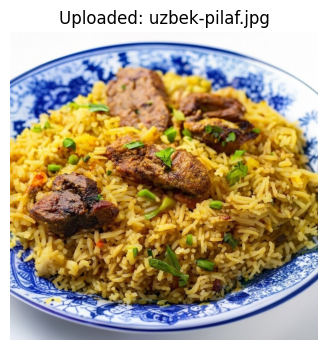

Prediction:
  ✅ pilaf: 100.00%
  ✅ hamburger: 0.00%
  ✅ kebab: 0.00%
  ✅ hot_dog: 0.00%


In [20]:
# ----------------------------------------
# Required Imports
# ----------------------------------------
import torch
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2
from PIL import Image
from google.colab import files
import io
import matplotlib.pyplot as plt

# ----------------------------------------
# Define Semantic Classes
# ----------------------------------------
CLASSES = ['hamburger', 'hot_dog', 'dessert', 'kebab', 'pilaf']  # Must match training order
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}

# ----------------------------------------
# Transform for Uploaded Images (no augmentations!)
# ----------------------------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# ----------------------------------------
# Load Model
# ----------------------------------------
model = mobilenet_v2(weights=None)
model.classifier[1] = torch.nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
model.load_state_dict(torch.load('/content/menu_detector.pth', map_location='cpu'))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
model = model.to(device)
model.eval()

# ----------------------------------------
# Upload & Predict
# ----------------------------------------
print("Upload one or more images of your food:")
uploaded = files.upload()

for image_name in uploaded.keys():
    image = Image.open(io.BytesIO(uploaded[image_name])).convert('RGB')

    # Display image
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis('off')
    plt.title(f'Uploaded: {image_name}')
    plt.show()

    # Predict
    image_tensor = transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(image_tensor)
        probs = torch.softmax(output, dim=1)[0]
        topk = torch.topk(probs, 4)

    print("Prediction:")
    for i in range(topk.indices.size(0)):
        label = CLASSES[topk.indices[i]]
        confidence = topk.values[i].item() * 100
        print(f"  ✅ {label}: {confidence:.2f}%")